In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 2026
THRESHOLD = 0.25

DATA_PATH = Path("../data/raw/processed/creditcard.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Check the CSV location before continuing."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# Inspect column types and non-null counts
df.info()

# Check missing values
print("Total missing values:", df.isna().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Inspect the target distribution
print("\nClass counts:")
print(df["Class"].value_counts().sort_index())

print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True).sort_index() * 100).round(4))

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
# Examine duplicate records
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.4f}%")

# Inspect class labels among duplicate rows
duplicate_rows = df.loc[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

print("\nClass distribution among all rows involved in duplicates:")
print(duplicate_rows["Class"].value_counts().sort_index())

# Create a modeling copy without exact duplicate rows
df_model = df.drop_duplicates().copy()

print("\nOriginal shape:", df.shape)
print("Modeling shape:", df_model.shape)
print("\nModeling class distribution:")
print(df_model["Class"].value_counts().sort_index())

print("\nModeling fraud prevalence:")
print(f"{df_model['Class'].mean() * 100:.4f}%")

Duplicate rows: 1081
Duplicate percentage: 0.3796%

Class distribution among all rows involved in duplicates:
Class
0    1822
1      32
Name: count, dtype: int64

Original shape: (284807, 31)
Modeling shape: (283726, 31)

Modeling class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Modeling fraud prevalence:
0.1667%


Transaction amount summary:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


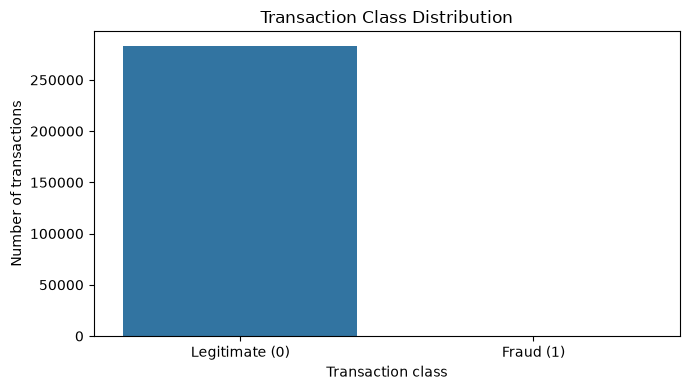

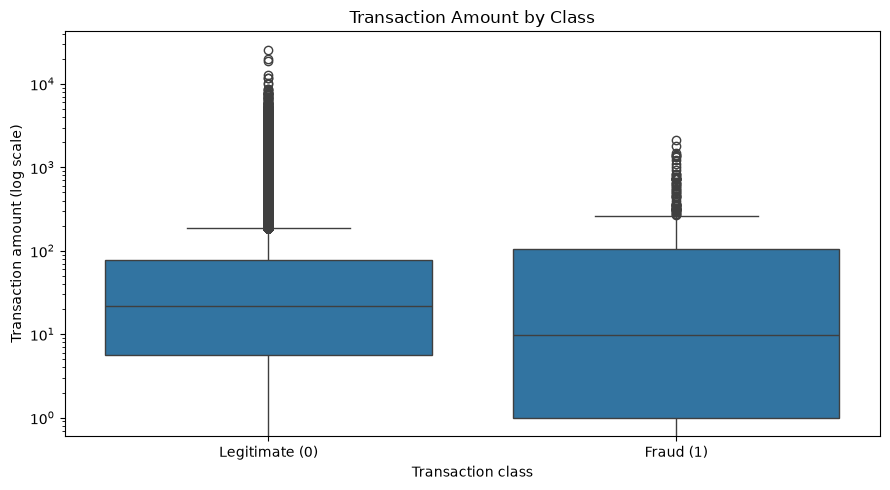

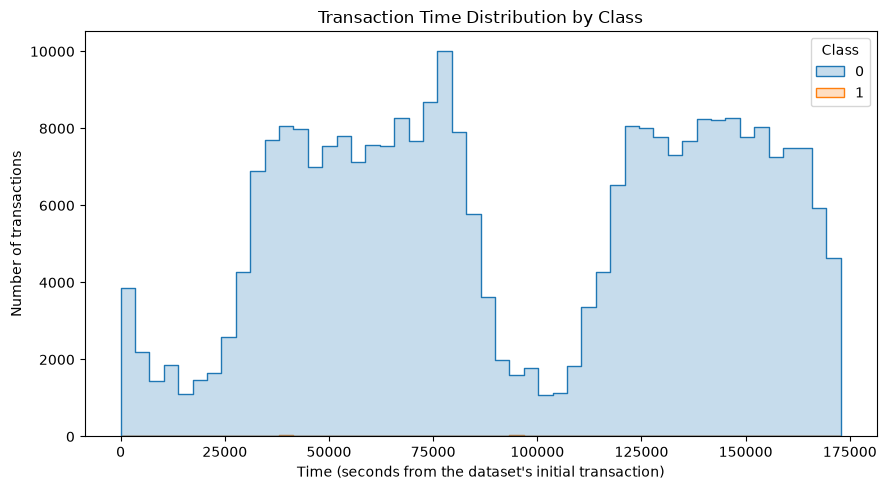

In [4]:

# Summary statistics for transaction amounts
print("Transaction amount summary:")
display(df_model.groupby("Class")["Amount"].describe())

# Fraud prevalence
class_counts = df_model["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
plt.xlabel("Transaction class")
plt.ylabel("Number of transactions")
plt.title("Transaction Class Distribution")
plt.tight_layout()
plt.show()

# Transaction amount distribution, excluding extreme visual compression
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_model, x="Class", y="Amount")
plt.yscale("log")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
plt.xlabel("Transaction class")
plt.ylabel("Transaction amount (log scale)")
plt.title("Transaction Amount by Class")
plt.tight_layout()
plt.show()

# Distribution of transaction time
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_model,
    x="Time",
    hue="Class",
    bins=50,
    element="step",
    stat="count",
    common_norm=False
)
plt.xlabel("Time (seconds from the dataset's initial transaction)")
plt.ylabel("Number of transactions")
plt.title("Transaction Time Distribution by Class")
plt.tight_layout()
plt.show()


,Correlation with Class
V17,-0.313498
V14,-0.293375
V12,-0.250711
V10,-0.206971
V16,-0.187186
V3,-0.182322
V7,-0.172347
V11,0.149067
V4,0.129326
V18,-0.105340


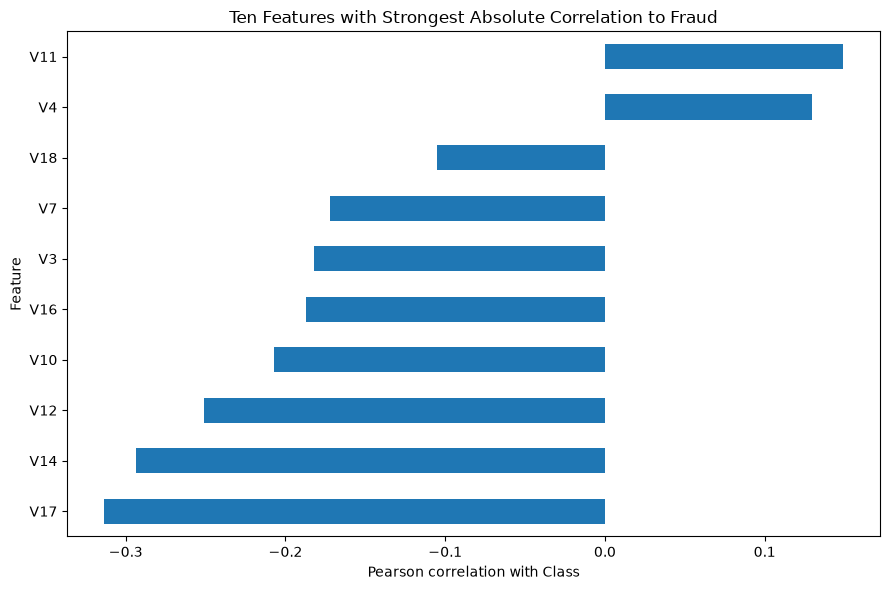

In [5]:

# Correlation of each numeric feature with the target
target_correlations = (
    df_model.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

display(target_correlations.to_frame(name="Correlation with Class"))

# Visualize the strongest correlations
top_correlations = target_correlations.head(10).sort_values()

plt.figure(figsize=(9, 6))
top_correlations.plot(kind="barh")
plt.xlabel("Pearson correlation with Class")
plt.ylabel("Feature")
plt.title("Ten Features with Strongest Absolute Correlation to Fraud")
plt.tight_layout()
plt.show()


Model Development and Evaluation

In [6]:

# Separate features and target
X = df_model.drop(columns=["Class"])
y = df_model["Class"]

# First: reserve 20% for final testing
X_development, X_final_test, y_development, y_final_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Then split the remaining 80% into 60% training and 20% validation
X_train_clean, X_val_clean, y_train_clean, y_val_clean = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_development,
)

# Summarize the split
for name, X_part, y_part in [
    ("Training", X_train_clean, y_train_clean),
    ("Validation", X_val_clean, y_val_clean),
    ("Final test", X_final_test, y_final_test),
]:
    print(
        f"{name:10s} | rows={len(X_part):,} | "
        f"fraud={int(y_part.sum()):,} | "
        f"fraud rate={y_part.mean() * 100:.4f}%"
    )

print("\nFeature count:", X_train_clean.shape[1])


Training   | rows=170,235 | fraud=283 | fraud rate=0.1662%
Validation | rows=56,745 | fraud=95 | fraud rate=0.1674%
Final test | rows=56,746 | fraud=95 | fraud rate=0.1674%

Feature count: 30


Random Forest Classifier

In [7]:

# Train the model using only the training subset
rf_clean = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)

rf_clean.fit(X_train_clean, y_train_clean)

# Predict fraud probabilities on the validation set
rf_val_scores_clean = rf_clean.predict_proba(X_val_clean)[:, 1]

print("Random Forest training complete.")
print("Validation probability count:", len(rf_val_scores_clean))
print(
    "Validation probability range:",
    round(rf_val_scores_clean.min(), 4),
    "to",
    round(rf_val_scores_clean.max(), 4),
)


Random Forest training complete.
Validation probability count: 56745
Validation probability range: 0.0 to 0.995


Validation Set Evaluation


In [8]:

# Convert predicted probabilities into class predictions
y_val_pred_clean = (
    rf_val_scores_clean >= THRESHOLD
).astype(int)

# Calculate evaluation metrics
val_precision = precision_score(
    y_val_clean, y_val_pred_clean, zero_division=0
)
val_recall = recall_score(
    y_val_clean, y_val_pred_clean, zero_division=0
)
val_f1 = f1_score(
    y_val_clean, y_val_pred_clean, zero_division=0
)
val_ap = average_precision_score(
    y_val_clean, rf_val_scores_clean
)
val_roc_auc = roc_auc_score(
    y_val_clean, rf_val_scores_clean
)

print(f"Decision threshold: {THRESHOLD:.2f}")
print(f"Precision:          {val_precision:.4f}")
print(f"Recall:             {val_recall:.4f}")
print(f"F1-score:           {val_f1:.4f}")
print(f"Average Precision:  {val_ap:.4f}")
print(f"ROC-AUC:            {val_roc_auc:.4f}")

# Confusion matrix: [[true negatives, false positives],
#                    [false negatives, true positives]]
cm = confusion_matrix(
    y_val_clean, y_val_pred_clean, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_val_clean,
        y_val_pred_clean,
        target_names=["Legitimate", "Fraud"],
        digits=4,
        zero_division=0,
    )
)


Decision threshold: 0.25
Precision:          0.9167
Recall:             0.8105
F1-score:           0.8603
Average Precision:  0.8155
ROC-AUC:            0.9344

Confusion Matrix:
[[56643     7]
 [   18    77]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9997    0.9999    0.9998     56650
       Fraud     0.9167    0.8105    0.8603        95

    accuracy                         0.9996     56745
   macro avg     0.9582    0.9052    0.9301     56745
weighted avg     0.9995    0.9996    0.9995     56745



Decision Threshold Analysis

In [9]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

threshold_results = []

for threshold in np.arange(0.10, 0.51, 0.05):
    y_pred = (rf_val_scores_clean >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_clean, y_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
    })

threshold_df = pd.DataFrame(threshold_results)

# Display the results without requiring Jinja2
display(threshold_df.round(4))


,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives
0,0.10,0.8265,0.8526,0.8394,81,17,14
1,0.15,0.8587,0.8316,0.8449,79,13,16
2,0.20,0.8876,0.8316,0.8587,79,10,16
3,0.25,0.9167,0.8105,0.8603,77,7,18
4,0.30,0.9167,0.8105,0.8603,77,7,18
5,0.35,0.9125,0.7684,0.8343,73,7,22
6,0.40,0.9125,0.7684,0.8343,73,7,22
7,0.45,0.9091,0.7368,0.8140,70,7,25
8,0.50,0.9067,0.7158,0.8000,68,7,27


Threshold Selection


In [10]:

# Selected using validation-set performance
THRESHOLD = 0.25

print(f"Selected decision threshold: {THRESHOLD:.2f}")
print(
    "Validation F1-score:",
    round(
        f1_score(
            y_val_clean,
            (rf_val_scores_clean >= THRESHOLD).astype(int),
        ),
        4,
    ),
)


Selected decision threshold: 0.25
Validation F1-score: 0.8603


Final Test Set Evaluation

In [11]:

# Generate predictions on the final test set
y_test_scores_clean = rf_clean.predict_proba(X_final_test)[:, 1]
y_test_pred_clean = (
    y_test_scores_clean >= THRESHOLD
).astype(int)

# Calculate final metrics
print(f"Decision threshold: {THRESHOLD:.2f}")
print(
    f"Precision:          {precision_score(y_final_test, y_test_pred_clean):.4f}"
)
print(
    f"Recall:             {recall_score(y_final_test, y_test_pred_clean):.4f}"
)
print(
    f"F1-score:           {f1_score(y_final_test, y_test_pred_clean):.4f}"
)
print(
    f"Average Precision:  {average_precision_score(y_final_test, y_test_scores_clean):.4f}"
)
print(
    f"ROC-AUC:            {roc_auc_score(y_final_test, y_test_scores_clean):.4f}"
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_final_test, y_test_pred_clean, labels=[0, 1]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_final_test,
        y_test_pred_clean,
        target_names=["Legitimate", "Fraud"],
        digits=4,
        zero_division=0,
    )
)


Decision threshold: 0.25
Precision:          0.9036
Recall:             0.7895
F1-score:           0.8427
Average Precision:  0.8522
ROC-AUC:            0.9557

Confusion Matrix:
[[56643     8]
 [   20    75]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9998     56651
       Fraud     0.9036    0.7895    0.8427        95

    accuracy                         0.9995     56746
   macro avg     0.9516    0.8947    0.9212     56746
weighted avg     0.9995    0.9995    0.9995     56746



## Model Evaluation Summary

A Random Forest classifier was developed to detect fraudulent credit card transactions using an anonymized credit card transaction dataset. The data was deduplicated before modeling, and a stratified 60/20/20 split was used to create training, validation, and held-out test subsets. The model was trained with 200 trees and `class_weight="balanced_subsample"` to account for the severe class imbalance.

A decision threshold of 0.25 was selected based on validation-set performance. On the held-out test set, the model achieved **90.36% precision, 78.95% recall, an F1-score of 84.27%, an Average Precision of 85.22%, and a ROC-AUC of 95.57%**.

At the selected threshold, the classifier correctly detected 75 of 95 fraudulent transactions, missed 20 fraudulent transactions, and incorrectly flagged 8 legitimate transactions. These results demonstrate promising fraud-detection performance on the held-out test subset, particularly in ranking transactions by fraud likelihood.

However, the results also show a trade-off between minimizing false alarms and detecting as much fraud as possible. Further work should examine alternative thresholds, compare the Random Forest against appropriate baseline models, and assess the implications of removing duplicate records. Because this evaluation uses a single split of a public dataset, the results should not be interpreted as proof of real-world production performance.

Model Evaluation Summary

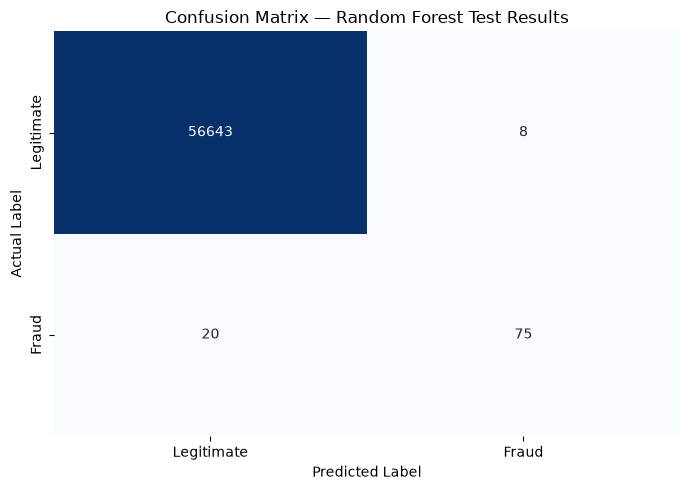

In [12]:

# Generate the confusion matrix using final test predictions
cm_test = confusion_matrix(
    y_final_test,
    y_test_pred_clean,
    labels=[0, 1],
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"],
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Random Forest Test Results")
plt.tight_layout()
plt.show()


Precision–Recall Curve

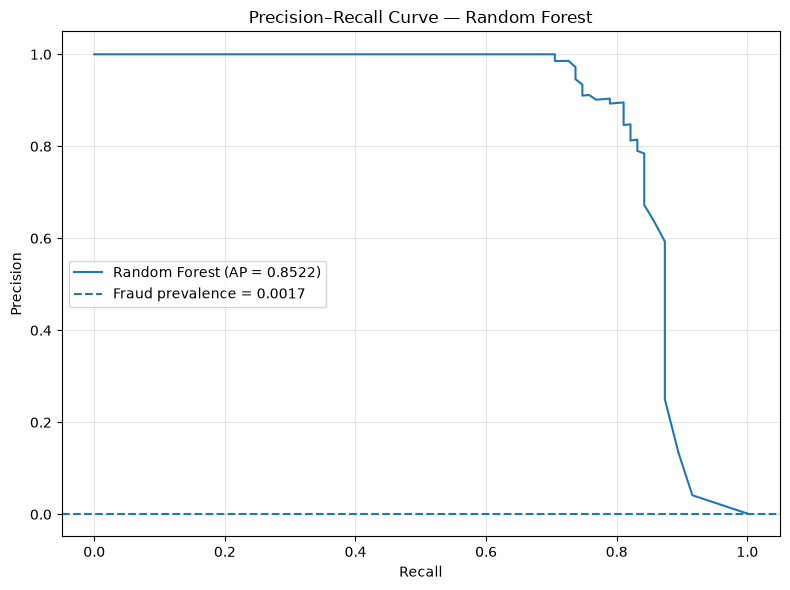

Test Average Precision: 0.8522


In [13]:

from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across different thresholds
test_precision, test_recall, test_thresholds = precision_recall_curve(
    y_final_test,
    y_test_scores_clean,
)

# Calculate Average Precision
test_ap = average_precision_score(
    y_final_test,
    y_test_scores_clean,
)

# Plot the precision-recall curve
plt.figure(figsize=(8, 6))

plt.plot(
    test_recall,
    test_precision,
    label=f"Random Forest (AP = {test_ap:.4f})",
)

# Baseline: proportion of fraud cases in the test set
fraud_prevalence = y_final_test.mean()
plt.axhline(
    y=fraud_prevalence,
    linestyle="--",
    label=f"Fraud prevalence = {fraud_prevalence:.4f}",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Test Average Precision: {test_ap:.4f}")


Baseline Model: Logistic Regression

In [14]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a baseline classification pipeline
lr_baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    ),
)

# Train using only the training data
lr_baseline.fit(X_train_clean, y_train_clean)

# Generate fraud probabilities on the validation set
lr_val_scores = lr_baseline.predict_proba(X_val_clean)[:, 1]

print("Logistic Regression baseline training complete.")
print("Validation probability count:", len(lr_val_scores))
print(
    "Validation probability range:",
    round(lr_val_scores.min(), 4),
    "to",
    round(lr_val_scores.max(), 4),
)



Logistic Regression baseline training complete.
Validation probability count: 56745
Validation probability range: 0.0 to 1.0


Baseline vs. Random Forest Comparison

In [15]:

# Generate binary predictions at the same threshold
lr_val_pred = (lr_val_scores >= THRESHOLD).astype(int)
rf_val_pred = (rf_val_scores_clean >= THRESHOLD).astype(int)

# Calculate metrics for each model
comparison_results = []

for model_name, y_scores, y_pred in [
    ("Logistic Regression", lr_val_scores, lr_val_pred),
    ("Random Forest", rf_val_scores_clean, rf_val_pred),
]:
    comparison_results.append({
        "Model": model_name,
        "Precision": precision_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, y_pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val_clean, y_scores
        ),
        "ROC-AUC": roc_auc_score(
            y_val_clean, y_scores
        ),
    })


comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df[
    [
        "Model",
        "Precision",
        "Recall",
        "F1-score",
        "Average Precision",
        "ROC-AUC",
    ]
].round(4)

display(comparison_df.style.hide(axis="index"))

Model,Precision,Recall,F1-score,Average Precision,ROC-AUC
Logistic Regression,0.021900,0.905300,0.042800,0.761200,0.962400
Random Forest,0.916700,0.810500,0.860300,0.815500,0.934400


Precision–Recall Curve: Model Comparison

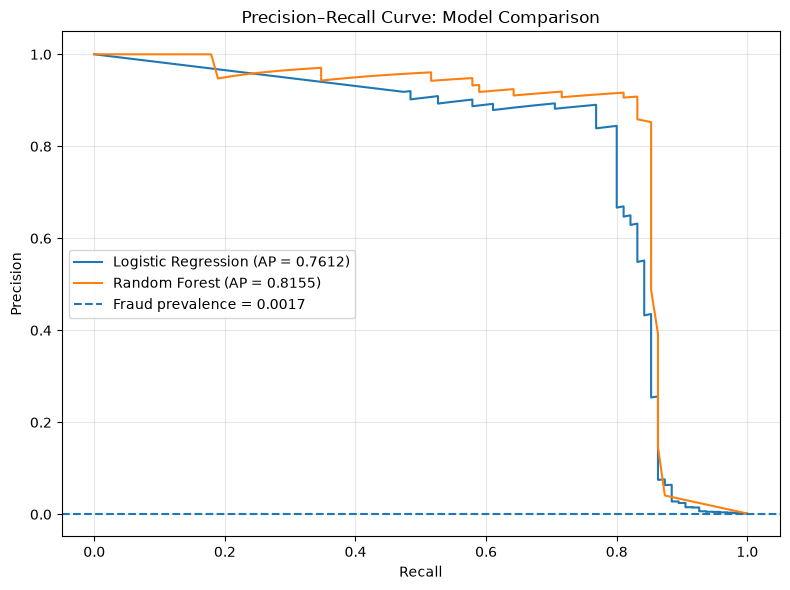

In [16]:

from sklearn.metrics import precision_recall_curve

lr_precision_curve, lr_recall_curve, _ = precision_recall_curve(
    y_val_clean, lr_val_scores
)

rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_val_clean, rf_val_scores_clean
)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_recall_curve,
    lr_precision_curve,
    label=f"Logistic Regression (AP = {average_precision_score(y_val_clean, lr_val_scores):.4f})",
)

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (AP = {average_precision_score(y_val_clean, rf_val_scores_clean):.4f})",
)

plt.axhline(
    y=y_val_clean.mean(),
    linestyle="--",
    label=f"Fraud prevalence = {y_val_clean.mean():.4f}",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Precision–Recall Curve Interpretation

The precision–recall curves compare Logistic Regression and Random Forest on the validation dataset. Average Precision (AP) summarizes the precision–recall trade-off across classification thresholds, making it useful for evaluating fraud detection models under severe class imbalance.

- **Random Forest** achieved a higher Average Precision of **0.8155**, indicating stronger overall precision–recall performance on the validation set.
- **Logistic Regression** achieved an Average Precision of **0.7612**. Although it had a higher ROC-AUC of **0.9624**, its lower Average Precision indicates weaker performance on the precision–recall trade-off.
- At the provisional classification threshold of **0.25**, Random Forest achieved a substantially better F1-score and precision, while Logistic Regression achieved higher recall but generated considerably more false positives.

Based on these validation results, Random Forest is the stronger candidate under the current evaluation criteria. However, the final model choice should also consider the operational cost of missed fraud versus false alarms. These findings are specific to this dataset and split and do not establish production-level performance.

In [17]:

from sklearn.metrics import precision_score, recall_score, f1_score

lr_threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):
    lr_pred = (lr_val_scores >= threshold).astype(int)

    lr_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, lr_pred, zero_division=0
        ),
    })

lr_threshold_df = pd.DataFrame(lr_threshold_results)

display(
    lr_threshold_df[
        ["Threshold", "Precision", "Recall", "F1-score"]
    ]
    .sort_values("F1-score", ascending=False)
    .head(10)
    .round(4)
    .reset_index(drop=True)
)


,Threshold,Precision,Recall,F1-score
0,0.95,0.3632,0.8526,0.5094
1,0.90,0.2462,0.8632,0.3832
2,0.85,0.2035,0.8632,0.3293
3,0.80,0.1643,0.8632,0.2761
4,0.75,0.1426,0.8632,0.2448
5,0.70,0.1180,0.8632,0.2076
6,0.65,0.0987,0.8632,0.1771
7,0.60,0.0817,0.8632,0.1492
8,0.55,0.0688,0.8737,0.1276
9,0.50,0.0597,0.8842,0.1119


In [18]:

top_lr_thresholds = (
    lr_threshold_df
    .sort_values("F1-score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print(
    top_lr_thresholds[
        ["Threshold", "Precision", "Recall", "F1-score"]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)


 Threshold  Precision  Recall  F1-score
    0.9500     0.3632  0.8526    0.5094
    0.9000     0.2462  0.8632    0.3832
    0.8500     0.2035  0.8632    0.3293
    0.8000     0.1643  0.8632    0.2761
    0.7500     0.1426  0.8632    0.2448
    0.7000     0.1180  0.8632    0.2076
    0.6500     0.0987  0.8632    0.1771
    0.6000     0.0817  0.8632    0.1492
    0.5500     0.0688  0.8737    0.1276
    0.5000     0.0597  0.8842    0.1119


In [19]:

best_lr_row = lr_threshold_df.loc[
    lr_threshold_df["F1-score"].idxmax()
]

print("Best Logistic Regression threshold (tested grid)")
print(f"Threshold: {best_lr_row['Threshold']:.2f}")
print(f"Precision: {best_lr_row['Precision']:.4f}")
print(f"Recall:    {best_lr_row['Recall']:.4f}")
print(f"F1-score:  {best_lr_row['F1-score']:.4f}")


Best Logistic Regression threshold (tested grid)
Threshold: 0.95
Precision: 0.3632
Recall:    0.8526
F1-score:  0.5094


In [20]:

lr_threshold_results_check = []

for threshold in np.arange(0.05, 0.96, 0.05):
    lr_pred_check = (lr_val_scores >= threshold).astype(int)

    lr_threshold_results_check.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_clean, lr_pred_check, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, lr_pred_check, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, lr_pred_check, zero_division=0
        ),
        "Predicted Fraud": int(lr_pred_check.sum()),
    })

lr_threshold_check_df = pd.DataFrame(lr_threshold_results_check)

print(
    lr_threshold_check_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


 Threshold  Precision  Recall  F1-score  Predicted Fraud
    0.0500     0.0050  0.9579    0.0100            18047
    0.1000     0.0084  0.9263    0.0167            10467
    0.1500     0.0125  0.9263    0.0247             7038
    0.2000     0.0169  0.9053    0.0332             5080
    0.2500     0.0219  0.9053    0.0428             3920
    0.3000     0.0280  0.8947    0.0542             3040
    0.3500     0.0338  0.8842    0.0652             2482
    0.4000     0.0412  0.8842    0.0788             2038
    0.4500     0.0497  0.8842    0.0941             1690
    0.5000     0.0597  0.8842    0.1119             1406
    0.5500     0.0688  0.8737    0.1276             1206
    0.6000     0.0817  0.8632    0.1492             1004
    0.6500     0.0987  0.8632    0.1771              831
    0.7000     0.1180  0.8632    0.2076              695
    0.7500     0.1426  0.8632    0.2448              575
    0.8000     0.1643  0.8632    0.2761              499
    0.8500     0.2035  0.8632  

In [21]:

lr_fine_threshold_results = []

for threshold in np.arange(0.90, 1.00, 0.01):
    lr_pred = (lr_val_scores >= threshold).astype(int)

    lr_fine_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "Predicted Fraud": int(lr_pred.sum()),
    })

lr_fine_threshold_df = pd.DataFrame(lr_fine_threshold_results)

print(
    lr_fine_threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


 Threshold  Precision  Recall  F1-score  Predicted Fraud
    0.9000     0.2462  0.8632    0.3832              333
    0.9100     0.2621  0.8526    0.4010              309
    0.9200     0.2718  0.8526    0.4122              298
    0.9300     0.2924  0.8526    0.4355              277
    0.9400     0.3189  0.8526    0.4642              254
    0.9500     0.3632  0.8526    0.5094              223
    0.9600     0.4050  0.8526    0.5492              200
    0.9700     0.4762  0.8421    0.6084              168
    0.9800     0.5683  0.8316    0.6752              139
    0.9900     0.6581  0.8105    0.7264              117


In [22]:

lr_upper_threshold_results = []

for threshold in [0.991, 0.992, 0.993, 0.994, 0.995, 0.996, 0.997, 0.998, 0.999]:
    lr_pred = (lr_val_scores >= threshold).astype(int)

    lr_upper_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, lr_pred, zero_division=0
        ),
        "Predicted Fraud": int(lr_pred.sum()),
    })

lr_upper_threshold_df = pd.DataFrame(lr_upper_threshold_results)

print(
    lr_upper_threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


 Threshold  Precision  Recall  F1-score  Predicted Fraud
    0.9910     0.6581  0.8105    0.7264              117
    0.9920     0.6638  0.8105    0.7299              116
    0.9930     0.6726  0.8000    0.7308              113
    0.9940     0.6786  0.8000    0.7343              112
    0.9950     0.6786  0.8000    0.7343              112
    0.9960     0.6847  0.8000    0.7379              111
    0.9970     0.7037  0.8000    0.7488              108
    0.9980     0.7170  0.8000    0.7562              106
    0.9990     0.7308  0.8000    0.7638              104


In [23]:

from sklearn.metrics import precision_recall_curve
import numpy as np

lr_precision_all, lr_recall_all, lr_thresholds_all = (
    precision_recall_curve(y_val_clean, lr_val_scores)
)

# The final precision/recall point has no corresponding threshold.
lr_f1_all = (
    2 * lr_precision_all[:-1] * lr_recall_all[:-1]
    / (
        lr_precision_all[:-1]
        + lr_recall_all[:-1]
        + 1e-12
    )
)

best_lr_idx = np.argmax(lr_f1_all)
best_lr_threshold = lr_thresholds_all[best_lr_idx]

print("Best Logistic Regression threshold on validation data")
print(f"Threshold: {best_lr_threshold:.6f}")
print(f"Precision: {lr_precision_all[best_lr_idx]:.4f}")
print(f"Recall:    {lr_recall_all[best_lr_idx]:.4f}")
print(f"F1-score:  {lr_f1_all[best_lr_idx]:.4f}")


Best Logistic Regression threshold on validation data
Threshold: 1.000000
Precision: 0.8902
Recall:    0.7684
F1-score:  0.8249


In [24]:

print("Maximum Logistic Regression validation score:",
      f"{lr_val_scores.max():.10f}")

print("Number of scores exactly equal to 1.0:",
      int(np.sum(lr_val_scores == 1.0)))

print("Number of scores greater than or equal to selected threshold:",
      int(np.sum(lr_val_scores >= best_lr_threshold)))

print("Validation fraud cases:",
      int(y_val_clean.sum()))


Maximum Logistic Regression validation score: 1.0000000000
Number of scores exactly equal to 1.0: 49
Number of scores greater than or equal to selected threshold: 82
Validation fraud cases: 95


In [25]:

from sklearn.metrics import precision_score, recall_score, f1_score

lr_best_val_pred = (
    lr_val_scores >= best_lr_threshold
).astype(int)

rf_best_val_pred = (
    rf_val_scores_clean >= THRESHOLD
).astype(int)

selected_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Threshold": best_lr_threshold,
        "Precision": precision_score(
            y_val_clean, lr_best_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, lr_best_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, lr_best_val_pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val_clean, lr_val_scores
        ),
        "ROC-AUC": roc_auc_score(
            y_val_clean, lr_val_scores
        ),
    },
    {
        "Model": "Random Forest",
        "Threshold": THRESHOLD,
        "Precision": precision_score(
            y_val_clean, rf_best_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clean, rf_best_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_clean, rf_best_val_pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val_clean, rf_val_scores_clean
        ),
        "ROC-AUC": roc_auc_score(
            y_val_clean, rf_val_scores_clean
        ),
    },
])

print(selected_model_comparison.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))


              Model  Threshold  Precision  Recall  F1-score  Average Precision  ROC-AUC
Logistic Regression     1.0000     0.8902  0.7684    0.8249             0.7612   0.9624
      Random Forest     0.2500     0.9167  0.8105    0.8603             0.8155   0.9344


In [26]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

# Predict fraud probabilities on the untouched test set.
lr_test_scores = lr_baseline.predict_proba(X_final_test)[:, 1]

# Apply the threshold selected using validation data.
lr_test_pred = (
    lr_test_scores >= best_lr_threshold
).astype(int)

print("Logistic Regression — Final Test Results")
print(f"Threshold:         {best_lr_threshold:.6f}")
print(f"Precision:         {precision_score(y_final_test, lr_test_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_final_test, lr_test_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_final_test, lr_test_pred, zero_division=0):.4f}")
print(f"Average Precision: {average_precision_score(y_final_test, lr_test_scores):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_final_test, lr_test_scores):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_final_test, lr_test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_final_test,
    lr_test_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0,
))


Logistic Regression — Final Test Results
Threshold:         1.000000
Precision:         0.9024
Recall:            0.7789
F1-score:          0.8362
Average Precision: 0.7527
ROC-AUC:           0.9879

Confusion Matrix:
[[56643     8]
 [   21    74]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.90      0.78      0.84        95

    accuracy                           1.00     56746
   macro avg       0.95      0.89      0.92     56746
weighted avg       1.00      1.00      1.00     56746



### Final Model Comparison and Selection

Two classification models were evaluated for credit card fraud detection: Logistic Regression as a linear baseline and Random Forest as the primary nonlinear model. Both models were trained on the same deduplicated dataset and evaluated using stratified training, validation, and held-out test sets.

The classification threshold for each model was selected using validation data. The final test set was reserved for evaluating the selected operating points.

On the held-out test set, Random Forest achieved an F1-score of **0.8427**, precision of **0.9036**, recall of **0.7895**, Average Precision of **0.8522**, and ROC-AUC of **0.9557**. It detected 75 of the 95 fraudulent transactions, missed 20, and generated 8 false positives.

Logistic Regression achieved an F1-score of **0.8362**, precision of **0.9024**, recall of **0.7789**, Average Precision of **0.7527**, and ROC-AUC of **0.9879**. It detected 74 fraudulent transactions, missed 21, and generated 8 false positives.

Based on F1-score, recall, and Average Precision, Random Forest was selected as the preferred model for this experiment. Logistic Regression remains a competitive baseline and achieved a higher ROC-AUC, illustrating that different evaluation metrics can favor different aspects of model performance.

These results should be interpreted within the limits of the experiment. The dataset is highly imbalanced, the test set contains only 95 fraudulent transactions, and exact duplicate removal is a modeling decision that may exclude genuine repeated transactions. The selected Logistic Regression threshold is also unusually high. Further validation across multiple splits, threshold stability analysis, and cost-sensitive evaluation would be necessary before considering deployment.

### Feature Importance Analysis

Feature importance was examined to identify which input variables contributed most to the Random Forest model's predictions. The analysis uses the model's impurity-based feature importance scores.

The dataset contains anonymized PCA-derived features (`V1`–`V28`), along with `Time` and `Amount`. Therefore, feature importance can indicate predictive relevance within this dataset, but it cannot directly establish the underlying real-world meaning or cause of fraudulent behavior.

In [27]:

feature_importance_df = pd.DataFrame({
    "Feature": X_train_clean.columns,
    "Importance": rf_clean.feature_importances_,
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False,
).reset_index(drop=True)

print("Top 15 Most Important Features")
print(
    feature_importance_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)


Top 15 Most Important Features
Feature  Importance
    V14      0.1729
     V4      0.1255
    V10      0.1053
    V12      0.1047
    V17      0.0817
    V11      0.0636
    V16      0.0614
     V3      0.0542
     V2      0.0245
     V7      0.0213
     V9      0.0193
    V21      0.0157
    V19      0.0142
    V18      0.0140
     V6      0.0110


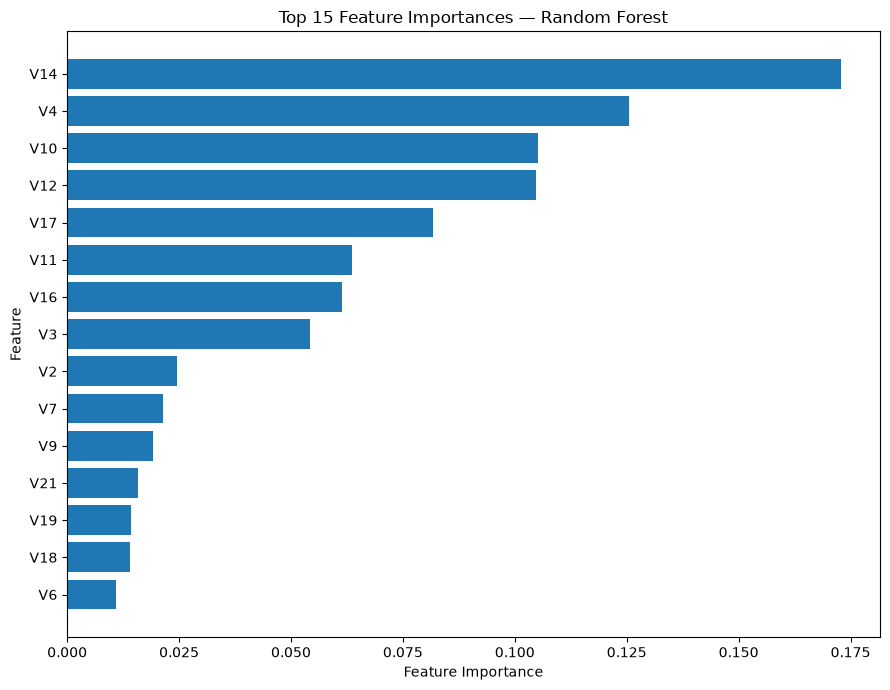

In [28]:
top_features = feature_importance_df.head(15).sort_values(
    "Importance", ascending=True
)
plt.figure(figsize=(9, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances — Random Forest")
plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The Random Forest model assigned the highest impurity-based feature importance to **V14 (0.1729)**, followed by **V4 (0.1255)**, **V10 (0.1053)**, and **V12 (0.1047)**. These four features collectively represent approximately 50.84% of the model's total feature importance.

The results suggest that these variables play a substantial role in the model's classification decisions. However, `V1`–`V28` are anonymized features derived through Principal Component Analysis (PCA), so their original financial meanings cannot be directly inferred from their feature names.

Feature importance measures how much a feature contributes to the Random Forest's impurity reduction; it does not establish causation or guarantee that a feature will remain important in other datasets. Further analysis, such as permutation importance or SHAP, could help assess the robustness and interpretability of these findings.

## Final Model Comparison and Conclusion

### Model Selection

Two classification models were evaluated for credit card fraud detection: Logistic Regression and Random Forest. Both models were trained on the same training dataset and evaluated using a held-out test set.

Based on the test-set results, **Random Forest was selected as the preferred model** because it achieved a higher F1-score (0.8427), higher recall (78.95%), and higher Average Precision (0.8522) than Logistic Regression.

Random Forest identified 75 of the 95 fraudulent transactions in the test set, with 8 false-positive predictions. Logistic Regression identified 74 fraudulent transactions, also with 8 false positives. Although Logistic Regression achieved a higher ROC-AUC of 0.9879 compared with Random Forest's 0.9557, Random Forest performed better in the selected-threshold classification metrics and Average Precision.

### Key Findings

- **Class imbalance:** Fraudulent transactions represented approximately 0.17% of the dataset after exact duplicate removal, making accuracy alone an unsuitable measure of model performance.
- **Model performance:** Random Forest achieved an F1-score of 0.8427 and Average Precision of 0.8522 on the test set.
- **Feature importance:** V14, V4, V10, and V12 had the highest impurity-based feature importance scores in the Random Forest model.
- **Threshold selection:** Classification thresholds were selected using validation data before final test-set evaluation.

### Limitations and Future Improvements

The dataset contains anonymized PCA-derived features, limiting direct interpretation of the underlying transaction characteristics. Removing exact duplicates may also remove legitimate repeated transactions. In addition, the evaluation uses a stratified random split rather than a time-based split, so it does not fully establish how the model would perform on future transactions.

Future work could investigate threshold optimization based on fraud-detection costs, probability calibration, permutation feature importance, and time-based validation. Further testing on newer transaction data would also be needed before considering deployment in a real-world fraud-monitoring system.

### Conclusion

This project demonstrates a machine-learning workflow for highly imbalanced credit card fraud detection, covering data quality assessment, exploratory data analysis, model training, validation-based threshold selection, test-set evaluation, and feature importance analysis. Random Forest was the stronger overall model under the selected evaluation criteria, while Logistic Regression provided a useful baseline with a higher ROC-AUC. Neither model should be considered production-ready without additional validation and operational testing.